# Tutorial — A simple glacier model

*Session 1, hands-on (≈ 1 hour). No IGM needed: only numpy and matplotlib.*

Run this notebook in your RenkuLab session (set up just before, see `session1/1c-setup-renku.md`): run the cells one by one, from top to bottom (Shift+Enter runs the current cell and moves to the next one). At the end of the afternoon, **Pause** your session (not *Delete*): your notebook will be there next week.

**Goals of this tutorial**
- Get familiar with a simple SIA-based glacier model in 1D (flowline) and 2D (map view)
- Understand how the equations of Lecture 1b (Glen's law, SIA, mass conservation, SMB) are implemented
- Perform simple numerical experiments: steady state, sensitivity to climate and ice softness, **response time**

Here we play with a simple glacier evolution model based on simplified equations of ice physics. In Session 2, we will use a more elaborate model (IGM) to model the evolution of a real glacier with a state-of-the-art approach. We start with a flowline ("1D") idealized glacier for simplicity.



# A flowline glacier (1D)

<img src="https://svs.gsfc.nasa.gov/vis/a000000/a003800/a003849/antarctica_flows_1_00120_1024x576.jpg" alt="Map of Antarctica" width="40%">

*Ice flow field in Antarctica, the pink areas (ice shelves where the ice is floating) display the zone for the ice is the fastest. Check a the [NASA website](https://svs.gsfc.nasa.gov/3849/) for animations.*

## Ice Deformation

### Glen's flow law

Ice is often considered a non-Newtonian fluid, meaning that its flow behavior is not linear with respect to stress. This unique characteristic is primarily due to ice's crystalline structure and the way it deforms under stress. Glen's flow law provides a mathematical description of this behavior, quantifying how ice flow is related to stress. According to Glen’s law, the ice strain rate $ \dot{\epsilon} $ is proportional to the applied stress $ \tau $ raised to a power n=3, expressed as:


$$ \dot{\epsilon} = A \tau^n $$

Here, $ A $ is a temperature-dependent flow parameter, its unit is $Pa^{-3} \, y^{-1} $. In IGM (Session 2), the same parameter is called `arrhenius` and is given in $MPa^{-3} \, y^{-1}$: the default value for temperate ice, `arrhenius: 78`, corresponds to $A = 7.8 \times 10^{-17} \, Pa^{-3} \, y^{-1}$. Glen's exponent is very commonly taken as n=3. This non-linear relation illustrates that as stress increases, the rate of ice deformation also increases but at an accelerating rate, which is a fundamental concept in understanding ice dynamics.

Glen's flow law, together with the momentum conservation equations, yields a set of Stokes equations, which can be solved to derive the ice flow velocity of an ice body subject to gravitational deformation.

### Shallow Ice Approximation (SIA)

The Shallow Ice Approximation (SIA) is a simplification of the Stokes equation that applies to ice flow in regions where the ice thickness is much smaller than its horizontal extent. This approximation is particularly useful for modeling ice sheets and glaciers, as it assumes that the vertical shear stress is negligible compared to the gravitational forces acting on the ice. Consequently, the SIA focuses on the balance between the driving stress from the surface slope and the resisting stress due to the ice's weight and friction at the base. The velocity of ice flow under the SIA can be expressed as:

$$ u (z) = -\frac{A}{2} \left( \rho g \frac{\partial z}{\partial x} \right)^3 \left( h^4 - (h -z)^4 \right), \qquad (1) $$

where $ u $ is the ice velocity, $ h $ is the ice thickness, $ \rho $ is the ice density, $ g $ is the acceleration due to gravity, and $ \frac{\partial z}{\partial x} $ is the slope of the ice surface.

The following sketch of code implements the SIA formula (1) and allows us to visualize the ice velocity along the ice thickness as a function of depth $z$, ice thickness $h$, surface slope $\frac{\partial z}{\partial x}$, $A$ ice softness parameter. Run the code for different parameters of $A$, $h$, and slope $\frac{\partial z}{\partial x}$, and check at how the ice velocity profile change.

✅ **Your turn!** 

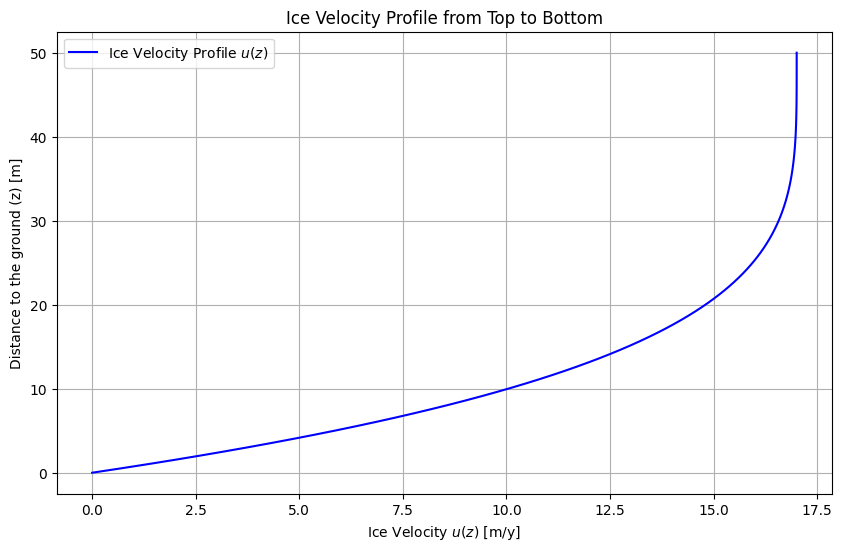

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# parameters
A = 1.0e-16  # Constant A, Arrhenius that determine the ice softness (Unit: $Pa^{-3} \, y^{-1} $)
rho = 910  # Density of ice in kg/m³
g = 9.81  # Acceleration due to gravity in m/s²
h = 50.0  # Total ice thickness in meters
dz_dx = -np.tan(np.radians(23))  # Slope (23 degrees)

z_values = np.linspace(0, h, 100)  # 100 points from 0 to h

# Calculate u(z) using the provided formula (1)
u_values = -0.5 * A * (rho * g * dz_dx)**3 * (h**4 - (h - z_values)**4)

# Plotting the profile (u(z) vs z)
plt.figure(figsize=(10, 6))
plt.plot(u_values, z_values, label='Ice Velocity Profile $u(z)$', color='blue')
plt.title('Ice Velocity Profile from Top to Bottom')
plt.xlabel('Ice Velocity $u(z)$ [m/y]')  # Adjust units based on context
plt.ylabel('Distance to the ground (z) [m]') 
plt.grid()
plt.legend()
plt.show()


## Mass Conservation

The principle of mass conservation is fundamental in fluid dynamics and applies to the evolution of ice sheets as well. In the context of ice flow, mass conservation asserts that the rate of change of ice thickness over time is equal to the difference between the ice accumulation and ablation. Mathematically, this can be expressed as:

$$ \frac{\partial h}{\partial t} + \frac{\partial q}{\partial x} = SMB(z) \qquad (2) $$

where $ h $ is the ice thickness, $q= \int_b^s u dz$ is the ice flux, and $ SMB(z) $ is the Surface Mass Balance term representing accumulation minus ablation, $t$ is time, and $x$ is the distance along the model.

## Ice sheet evolution equation

When combining the Shallow Ice Approximation (1), which relates the flux $ q $ to the ice thickness and the slope of the ice surface, with the mass conservation equation (2), we obtain a nonlinear diffusive equation (given here in one dimension) that predicts the evolution of the geometry of an ice sheet, as follows:

$$ \frac{\partial h}{\partial t} =  \frac{\partial}{\partial x} \left( D(h) \frac{\partial z}{\partial x} \right) + SMB(z), \qquad (3) $$

where $h$ is the ice thickness, $D(h)$ is the dynamic diffusivity of the ice defined as

$$ D(h) = \frac{2 A}{5} (\rho g)^3 h^5 \left( \frac{\partial z}{\partial x} \right)^2. $$

## Numerical solving


Equation (3) must be solved numerically for doing the experiments proposed below.

For that purpose, the code below "discretizes" (3) using finite differences to approximate the time derivative, this yields to the following update rule:

$$ h^{n+1} = h^{n} + dt \left(  \frac{\partial}{\partial x} \left( D(h^n) \frac{\partial z^n}{\partial x} \right) + SMB^n(z) \right), $$

where we compute the ice thickness variable $h$ at time $t^0$, $t^1$, $t^2$, ..., $t^n$, ...

The same way, the domain of the glacier is discretized into small intervall, $x^0$, $x^1$, ..., $x^m$, ... and the ice thickness evolution is computed only at these points of the discretization.

📘 **To learn more** about the numerical solving (finite differences, nonlinear diffusion, stability of the time step), see Session 10 of the course *Modélisation numérique* (in French): [lecture](https://jouvetg.github.io/modnum/10_cours/10_cours.html), [tutorial](https://jouvetg.github.io/modnum/10_tutoriel/10_tutoriel.html), [exercises](https://jouvetg.github.io/modnum/10_exercice/10_exercice.html).

## Climate

The snow accumulation budget (which turns into ice) at altitude and ice melt depends on precipitation and temperature. This mass balance $SMB(z)$ is commonly defined as a function of altitude (next figure to the right) and depends on three factors: 

- 1) a slope that controls the mass balance gradient $b_\mathrm{grad}$, 
- 2) a maximum value for accumulation $b_\mathrm{max}$, 
- 3) the altitude of the equilibrium line $z_\mathrm{ELA}$ beyond which ice accumulates and below which ice melts. 

Mathematically, $SMB(z)$ can thus be expressed as:

$$ SMB(z) = \min ( b_\mathrm{grad} (z-z_\mathrm{ELA}), b_\mathrm{max} ). \qquad (4) $$

The code in the next block gives an example of SMB function as function of $z$.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

b_max=1
grad_b=0.001
z_ELA=3000 

def smb_fct(elev):
    return np.minimum(grad_b * (elev - z_ELA), b_max)

elev = np.arange(1000, 5000, 20) 
plt.axhline(y=z_ELA, color='r', linestyle='--', label='y = z_ELA')
plt.plot(smb_fct(elev), elev)
plt.ylabel('Altitude [m]')
plt.xlabel('SMB [m/y]')
plt.title('Example of SMB  as a function of elevation')


## Numerical Implementation

Here, we will solve numerically equation (3) with surface mass balance parametrization (4) in order to conduct simple numerical experiments of glacier evolution for different climate configurations. The model setup is as follows:

- We assume a glacier that forms along the axis $ x $ in one dimension.
- Use an initial ice thickness of 0 m. 
- As boundary conditions, fix the ice thickness at both ends of the model to zero. 
- Use the following logarithmic function to define the bedrock:
\begin{equation}
z_{bed}(x)  = 13522.8 - 1000 \times \log(x + 1000) 
\end{equation}
- The additional parameters are given in the table below. 

The code below permits to solve and visualize the temporal evolution of the results of the model.

| **Parameters**                             | **Values**                 |
|--------------------------------------------|-----------------------------|
| physical constant $ A $               | $ 2.5 \times 10^{-15} [Pa^{-3} yr^{-1}]$ |
| model length $ L $                      | 140 km                      |
| initial ice thickness                      | 0 m                         |
| maximum time step $ dt_{max} $         | 1 y                         |
| ice density $ \rho_{\mathrm{ice}} $    | 910 $kg/m^{3}$             |
| gravitational constant $ g $            | 9.81 m $s^{-2}$          |
| altitude of the equilibrium line $ z_{\mathrm{ELA}} $ | 3000 m       |
| maximum mass balance $ b_{\mathrm{max}} $ | 0.3 m/yr                 |
| mass balance gradient $ b_{\mathrm{grad}} $ | 0.001                  |
| total time                                | 5000 y                     |

*Parameters for the exercises.*

**Note:** It is important to check the units. Since
- $ Pa = Kg \, m^{-1} \,  s^{-2}$ 
- $[A] = Pa^{-3} \, y^{-1} $ 
- $[\rho g] = Kg \, m^{-3} \, m  \, s^{-2} = Kg \, m^{-2} \, s^{-2} = Pa \, m^{-1}$,

we have $[A(\rho g)^3 ] = Pa^{-3} \, y^{-1} \, Pa^3 \, m^{-3} = m^{-3} y^{-1} $  and therefore $[D] = m^2 y^{-1} $, which is consistent.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

def model_glacier_1d(smb_fct, A, total_time):
    """Flowline glacier model: solves dh/dt = d/dx(D dz/dx) + SMB, starting from no ice.
    smb_fct(surface, time) must return the SMB (m/y) at each point and the ELA (m)."""

    # Physical parameters
    length = 1.4e5                        # length of the domain (m)
    rho_g = 910 * 9.81                    # ice density (kg/m^3) x gravity (m/s^2)
    diff_const = (2.0/5.0) * A * rho_g**3 # all the constants of the diffusivity D lumped together

    # Grid in space
    nx = 201                              # number of grid points
    dx = length / (nx - 1)                # distance between two grid points (m)
    x = np.linspace(0, length, nx)        # x-coordinate of the grid points (m)

    # Time stepping
    dt_max = 1                            # maximum time step (y)
    plot_every = 500                      # plot every 'plot_every' time steps

    # Initial state
    bed = - 1000 * np.log(x + 1000) + 13522.8   # bedrock elevation (m)
    thickness = np.zeros(nx)                    # ice thickness (m): no ice at the start
    surface = bed + thickness                   # ice surface elevation (m)

    time = 0.0                            # current time (y)
    step = 0                              # time step counter

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Time loop: each iteration moves the glacier forward by dt years
    while time < total_time:

        # 1. Ice flow (SIA). D, slope and flux are computed between two grid points (nx-1 values)
        thickness_mid = 0.5 * (thickness[:-1] + thickness[1:])   # thickness between grid points
        slope = np.diff(surface) / dx                            # surface slope dz/dx
        D = diff_const * thickness_mid**5 * slope**2             # diffusivity D(h) (m^2/y)
        flux = -D * slope                                        # ice flux q = -D dz/dx (m^2/y)
        dhdt_flow = -np.diff(flux) / dx                          # thickness change due to flow -dq/dx (m/y), at the inner points

        # 2. Time step: the largest stable one for an explicit scheme (CFL condition), at most dt_max
        #    (+1e-10 avoids a division by 0 when there is no ice yet)
        dt = min(dt_max, dx**2 / (2.1 * np.max(D) + 1e-10))

        # 3. Update the thickness with the ice flow (inner points only)
        thickness[1:-1] += dt * dhdt_flow

        # 4. Update the thickness with the surface mass balance (accumulation - ablation)
        smb, z_ela = smb_fct(surface, time)
        thickness[1:-1] += dt * smb[1:-1]

        # 5. No negative ice (where ablation removed more than the available ice)
        thickness[thickness < 0] = 0

        # 6. Boundary conditions: no ice at both ends of the domain
        thickness[0] = 0
        thickness[-1] = 0

        # 7. New ice surface, next time step
        surface = bed + thickness
        time += dt
        step += 1

        # Plot every 'plot_every' steps
        if step % plot_every == 0:

            clear_output(wait=True)      # replace the previous figure
            ax1.cla()
            ax2.cla()

            # Left: glacier geometry
            ax1.plot(x / 1000, surface, 'b', linewidth=2)               # ice surface
            ax1.plot(x / 1000, bed, 'k', linewidth=1)                   # bedrock
            ax1.plot([x[0], x[-1] / 1000], [z_ela, z_ela], 'g')         # ELA
            ax1.set_ylim([np.min(bed), np.max(bed)])
            ax1.set_ylabel('Elevation, m')
            ax1.set_xlabel('Distance, km')
            ax1.set_title('Glacier after ' + str(int(time)) + ' years')

            # Right: surface mass balance along the flowline
            ax2.plot(x / 1000, smb, 'b', linewidth=2)
            ax2.plot([x[0], x[-1] / 1000], [0, 0], 'k', linewidth=1)
            ax2.set_title('Surface mass balance')
            ax2.set_xlabel('Distance, km')
            ax2.set_ylabel('SMB, m/y')

            display(fig)

Let's now run the model for different configurations of SMB function and ice flow parameter ($A$) and explore their influence on the result.
Take the following code, and play with it to answer the following questions:
   - How long does it take to reach a steady state (roughly) ?
   - change the equilibrium line altitude (ELA) from 3000 to 4000, what do you observe?
   - change the surface mass balance gradient grad_b (multiply and divide by 3), what do you observe?
   - change the ice flow parameter, taking one order of magnitude less (harder ice), and one more (softer), what do you observe?

✅ **Your turn!** 

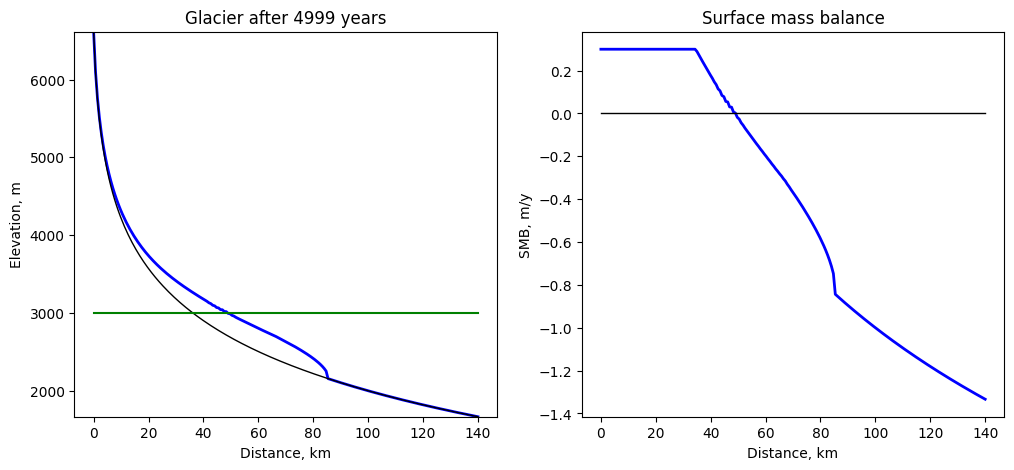

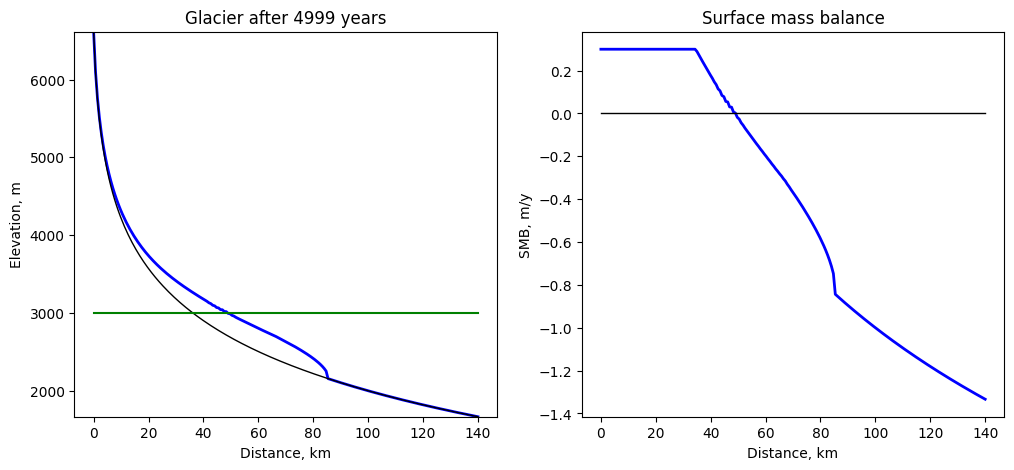

In [3]:
import numpy as np

b_max = 0.3        # maximum mass balance (m/y)
grad_b = 0.001     # mass balance gradient (m/y per m of elevation)
z_ELA = 3000       # equilibrium line altitude (m)
A = 2.5e-15        # ice softness, Glen's law (Pa^-3 y^-1)
total_time = 5000  # duration of the simulation (y)

def smb_fct(surface, time):
    # SMB linear in elevation, capped at b_max; returns the SMB and the ELA (for the plot)
    return np.minimum(grad_b * (surface - z_ELA), b_max), z_ELA

model_glacier_1d(smb_fct, A, total_time)

In the next exercise, we will make the ELA vary with time, following a cosine curve to mimic a series of cooling and warming events as follows:

Text(0.5, 1.0, 'Example of ELA as a function of time with a period of 4000 years')

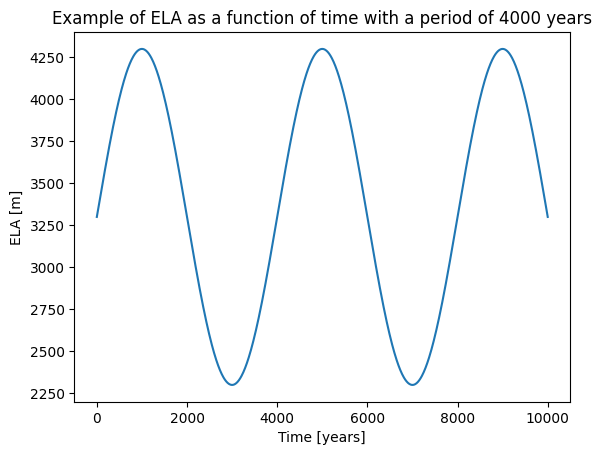

In [4]:
time = np.arange(0, 10001, 10) 
plt.plot(time, 3300 + 1000 * np.sin(time * np.pi / 2000))
plt.xlabel('Time [years]')
plt.ylabel('ELA [m]')
plt.title('Example of ELA as a function of time with a period of 4000 years')

Observe the time lapse between the minimum (resp. maximum) in ELA, and the time the glacier reach its maximum (resp. minimum). This is due to the fact that glacier have a certain inertia as system. Try shorter and longer cycles (`freq` is half the period of the cycle, in years). How do the lag and the amplitude of the glacier response change? Compare the lag with the response time $\tau \approx H / (-b_{terminus})$ of Lecture 1a. In Session 3 (exploration B3), you will do the same experiment with IGM on your own glacier. 
✅ **Your turn!** 

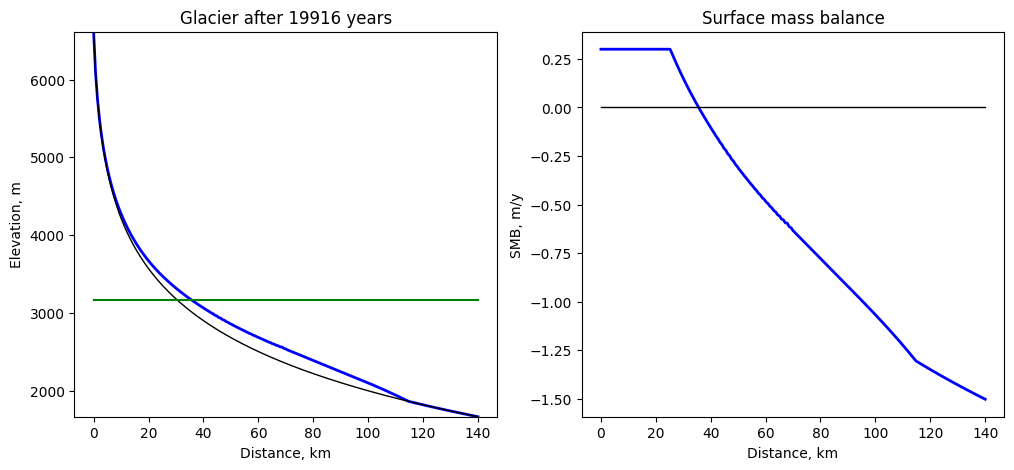

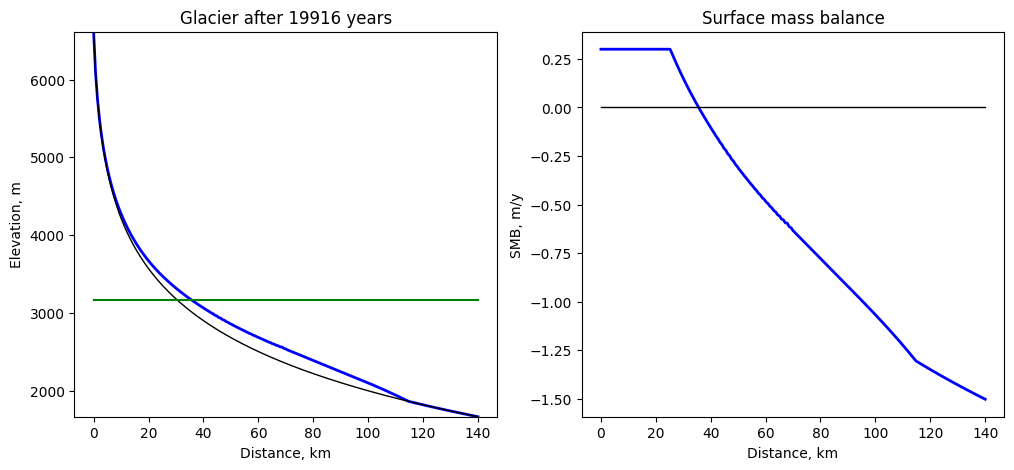

In [5]:
import numpy as np

b_max = 0.3        # maximum mass balance (m/y)
grad_b = 0.001     # mass balance gradient (m/y per m of elevation)
A = 2.5e-14        # ice softness, Glen's law (Pa^-3 y^-1)
freq = 2000        # half-period of the ELA cycle (y)
total_time = 20000 # duration of the simulation (y)

def ela_fct(time):
    # ELA oscillating around 3300 m, +/- 1000 m
    return 3300 + 1000 * np.sin(time * np.pi / freq)

def smb_fct(surface, time):
    # SMB linear in elevation, capped at b_max; returns the SMB and the ELA (for the plot)
    return np.minimum(grad_b * (surface - ela_fct(time)), b_max), ela_fct(time)

model_glacier_1d(smb_fct, A, total_time)

# A glacier in map view (2D): Gorner Glacier

We will now consider a more realistic situation: a glacier in map view (2D), namely Gorner Glacier located near Zermatt.

<img src="https://images.contenthub.dev/xshiytapvw9a/e404ac0c4deb0f9ef3d3bd6859603bb2/Gornergletscher%20Wanderung%20Rotenboden.jpg?fm=avif&fit=fill&q=45&h=640&w=1140"  width="50%">

*Gorner Glacier*

The objective of this exercise is to implement the ice equation to simulate a glacial landscape. In 2D, the evolution of ice thickness is represented by 

\begin{equation}
\frac{\partial h}{\partial t} - \frac{\partial}{\partial x} \left( D(h,z) \frac{\partial z}{\partial x} \right) - \frac{\partial}{\partial y} \left( D(h,z) \frac{\partial z}{\partial y} \right) =  SMB(z), \quad (1)
\end{equation}

where $ h $ is the ice thickness, $ t $ is time, $ b $ is the mass balance (accumulation minus surface ablation), $ D $ is the dynamic diffusivity of the ice, and $ z $ is the altitude of the ice surface. The non-linearity arises from the diffusivity constant $ D $, which itself depends on the local ice thickness $ h $ and the slope of the ice surface:

\begin{equation}
D(h,z) = \frac{2 A}{5} (\rho g)^3 h^5 ||\nabla S||^2 \qquad (2)
\end{equation}

where $ ||\nabla S|| $ is the norm of the local slope of the ice surface. At first glance, the problem is very similar to the 1D case, but the exact positioning of all values on the model grid is more complex in 2D. This 2D model and the Gorner Glacier experiment are explained in detail in Session 11 of the course *Modélisation numérique* (in French): [lecture](https://jouvetg.github.io/modnum/11_cours/11_cours.html), [tutorial](https://jouvetg.github.io/modnum/11_tutoriel/11_tutoriel.html), [exercises](https://jouvetg.github.io/modnum/11_exercice/11_exercice.html).

The following code implements the model with the following setup:

- Use an initial ice thickness of 0 m, and maintain a thickness of 0 at the edges of the model (boundary conditions). 
- The bedrock topography is given in the file `topg.txt`
- The rest of the parameters are given in the table below. 

| **Parameters:**                                   | **Values:**                  |
|--------------------------------------------------|-------------------------------|
| initial ice thickness                             | 0 m                           |
| ice density $ \rho_\mathrm{ice} $                | 910 kg/m$^3$                 |
| physical constant $ A $                           | $ 2.5 \times 10^{-18} Pa^{-3} yr^{-1} $ | 
| maximum mass balance $ b_\mathrm{max} $          | 0.3 m/yr                     |
| mass balance gradient $ b_\mathrm{grad} $        | 0.002                          |
| total time                                       | 5000 y                        |

✅ **Your turn!** 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

def model_glacier_2d(smb_fct):
    """Map-view (2D) glacier model of the Gorner Glacier area: solves
    dh/dt = div(D grad z) + SMB, starting from no ice. smb_fct(surface) returns the SMB (m/y)."""

    # Physical parameters
    total_time = 5000   # duration of the simulation (y)
    rho = 910.0         # ice density (kg/m^3)
    g   = 9.81          # gravity (m/s^2)
    A   = 2.5e-18       # ice softness, Glen's law (Pa^-3 y^-1)
    x_zermatt = 6327    # x-coordinate of Zermatt (m)
    y_zermatt = 14672   # y-coordinate of Zermatt (m)

    # Bedrock topography of the Gorner Glacier area (one point out of two -> 200 m grid)
    bed = np.loadtxt('topg.txt')[::2, ::2]
    ny, nx = bed.shape  # number of grid points in y and x

    # Grid in space
    dx = 200            # grid spacing in x (m)
    dy = 200            # grid spacing in y (m)
    length_x = dx * nx  # size of the domain in x (m)
    length_y = dy * ny  # size of the domain in y (m)

    # Time stepping
    plot_every = 1000   # plot every 'plot_every' time steps
    dt_max = 1          # maximum time step (y)
    dt = dt_max         # current time step (y)

    # Initial state
    thickness = np.zeros((ny, nx))   # ice thickness (m): no ice at the start
    surface = bed + thickness        # ice surface elevation (m)
    time = 0                         # current time (y)
    step = 0                         # time step counter

    extent = [0, length_x / 1000, 0, length_y / 1000]   # map extent in km, for the plots

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), dpi=100)

    s = ax1.imshow(surface, extent=extent, cmap='terrain', origin='lower', vmin=0, vmax=4800)
    fig.colorbar(s, ax=ax1, orientation='horizontal', label='Elevation (m)')

    ss = ax2.imshow(np.where(thickness > 0, thickness, np.nan), extent=extent, cmap='jet', origin='lower', vmin=0, vmax=1000)
    fig.colorbar(ss, ax=ax2, orientation='horizontal', label='Ice Thickness (m)')

    # Time loop: each iteration moves the glacier forward by dt years
    while time < total_time:

        time += dt
        step += 1

        # 1. Thickness at the centre of each cell of 4 grid points, size (ny-1, nx-1)
        thickness_mid = 0.25 * (thickness[:-1, :-1] + thickness[1:, 1:] + thickness[:-1, 1:] + thickness[1:, :-1])

        # 2. Surface slope at the same cell centres, size (ny-1, nx-1)
        slope_x = np.diff(surface, axis=1) / dx                 # dz/dx between two points in x
        slope_y = np.diff(surface, axis=0) / dy                 # dz/dy between two points in y
        slope_x = 0.5 * (slope_x[:-1, :] + slope_x[1:, :])      # averaged to the cell centres
        slope_y = 0.5 * (slope_y[:, :-1] + slope_y[:, 1:])
        slope_norm = np.sqrt(slope_x**2 + slope_y**2)           # norm of the surface slope |grad z|

        # 3. Diffusivity D(h, z) at the cell centres (m^2/y), size (ny-1, nx-1)
        D = (2.0/5.0) * A * (rho * g)**3.0 * thickness_mid**5 * slope_norm**2

        # 4. Time step: the largest stable one for an explicit scheme (CFL condition), at most dt_max
        #    (+1e-10 avoids a division by 0 when there is no ice yet)
        dt = min(min(dx, dy)**2 / (4.1 * np.max(D) + 1e-10), dt_max)

        # 5. Ice flux q = -D grad z in x, between two grid points in x, size (ny-2, nx-1)
        flux_x = -(0.5 * (D[:-1, :] + D[1:, :])) * np.diff(surface[1:-1, :], axis=1) / dx

        # 6. Ice flux in y, between two grid points in y, size (ny-1, nx-2)
        flux_y = -(0.5 * (D[:, :-1] + D[:, 1:])) * np.diff(surface[:, 1:-1], axis=0) / dy

        # 7. Thickness change due to flow, -div(q), at the inner points, size (ny-2, nx-2)
        dhdt_flow = -(np.diff(flux_x, axis=1) / dx + np.diff(flux_y, axis=0) / dy)
        thickness[1:-1, 1:-1] += dt * dhdt_flow

        # 8. Thickness change due to the surface mass balance (accumulation - ablation)
        smb = smb_fct(surface)
        thickness[1:-1, 1:-1] += dt * smb[1:-1, 1:-1]

        # 9. No negative ice (the borders stay at 0: no ice at the edges of the domain)
        thickness = np.maximum(thickness, 0)

        # 10. New ice surface
        surface = bed + thickness

        # Plot every 'plot_every' steps
        if step % plot_every == 0:

            clear_output(wait=True)      # replace the previous figure
            ax1.cla()
            ax2.cla()

            # Left: ice surface elevation, Zermatt as a black dot
            ax1.imshow(surface, extent=extent, cmap='terrain', origin='lower')
            ax1.plot(x_zermatt / 1000, y_zermatt / 1000, 'k', marker='o', markersize=10)
            ax1.set_title('Ice Surface at ' + str(int(time)) + ' y')
            ax1.set_xlabel('Distance, km')
            ax1.set_ylabel('Distance, km')
            ax1.axis('equal')

            # Right: ice thickness (no colour where there is no ice)
            ax2.imshow(np.where(thickness > 0, thickness, np.nan), extent=extent, cmap='jet', origin='lower')
            ax2.plot(x_zermatt / 1000, y_zermatt / 1000, 'k', marker='o', markersize=10)
            ax2.set_title('Ice Thickness at ' + str(int(time)) + ' y')
            ax2.set_xlabel('Distance, km')
            ax2.set_ylabel('Distance, km')
            ax2.axis('equal')
            display(fig)

Currently, the ELA of alpine glaciers is around 3000 m. Run the model until the glacier is approximately in equilibrium (5000 years), and compare your results to the Gorner Glacier with the images on [map.geo.admin.ch](https://map.geo.admin.ch). Try to find the ELA that produces a glacier (in equilibrium) that best fits the current state of the Gorner Glacier. To help you, the city of Zermatt is indicated with a black dot.


In [ ]:
import numpy as np

b_max = 0.3      # maximum mass balance (m/y)
grad_b = 0.002   # mass balance gradient (m/y per m of elevation)
z_ELA = 3100     # equilibrium line altitude (m)

def smb_fct(surface):
    # SMB linear in elevation, capped at b_max
    return np.minimum(grad_b * (surface - z_ELA), b_max)

model_glacier_2d(smb_fct)

## Wrap-up

Before leaving, make sure you can answer:
- What controls the steady-state length of the glacier? (ELA, SMB gradient, ice softness $A$)
- Why is there a lag between a climate change (ELA) and the glacier response? What controls this response time?
- What are the limits of this simple model (no sliding, SIA, simple SMB, no real data)?

➡️ In Session 2, IGM will solve a more complete ice-flow model on **real** glaciers, with data downloaded automatically.
